# 03 · Model 1 — Elastic Net (linear regression)

**Idea:** predict RUL as a **weighted sum** of the features:
`RUL ≈ w1·feature1 + w2·feature2 + … + b`

Elastic Net adds a **penalty** on large weights:
* **L1 part** → sets useless weights to exactly 0 (automatic feature selection)
* **L2 part** → keeps correlated features (like our sensors) stable

Features must be **scaled** first (they have very different units), so a `StandardScaler` is the first step of the pipeline.
It is our **simplest model** — easy to explain, but it can only learn straight-line relationships.


> 💡 Cells marked with **⋯** are hidden because they only contain plotting or helper code. Click them to expand.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import joblib
from sklearn.base import clone
from sklearn.model_selection import GridSearchCV, GroupKFold
from sklearn.linear_model import ElasticNet
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from utils import load_features, evaluate, plot_validation, plot_test, stage_table, save_results, savefig
from utils import COLORS, MODELS, RUL_CAP, SEED

NAME = "Elastic Net"

## 1. Load the features (made in notebook 02)

In [2]:
train, test, FEATURES = load_features()
tr = train[train["split"] == "train"]
val = train[train["split"] == "val"]

X_train, y_train, groups = tr[FEATURES], tr["RUL"], tr["unit"]
X_val, y_val = val[FEATURES], val["RUL"]
print(f"Training engines: {tr['unit'].nunique()} | Validation engines: {val['unit'].nunique()} | Features: {len(FEATURES)}")

Training engines: 80 | Validation engines: 20 | Features: 71


## 2. Train and tune the model
We try a few settings with **GridSearchCV** and keep the best one.

* **3-fold `GroupKFold`** on the 80 training engines → one engine is never in two folds (no leakage).
* Score = **RMSE** (lower is better).
* The 20 validation engines are **not** used here — only afterwards, to compare models fairly.

In [3]:
base_model = Pipeline([("scaler", StandardScaler()),                       # scale features (fitted on training data only)
                       ("model", ElasticNet(max_iter=10000, random_state=SEED))])
param_grid = {"model__alpha": [0.01, 0.1, 1.0],        # strength of the penalty
              "model__l1_ratio": [0.2, 0.5, 0.9]}      # mix between L1 and L2

search = GridSearchCV(base_model, param_grid, cv=GroupKFold(n_splits=3),
                      scoring="neg_root_mean_squared_error", n_jobs=-1)
search.fit(X_train, y_train, groups=groups)
model = search.best_estimator_
print("Best settings:", search.best_params_)

Best settings: {'model__alpha': 1.0, 'model__l1_ratio': 0.9}


## 3. Results on the validation engines
* **RMSE** — typical error in cycles (big mistakes count more)
* **MAE** — average error in cycles
* **R²** — how much of the variation is explained (1 = perfect)

In [4]:
val_pred = np.clip(model.predict(X_val), 0, RUL_CAP)     # RUL can't be below 0 or above the cap
pd.DataFrame([evaluate(y_val, val_pred)], index=[NAME + " (validation)"])

,RMSE,MAE,R2
Elastic Net (validation),15.04,12.01,0.87


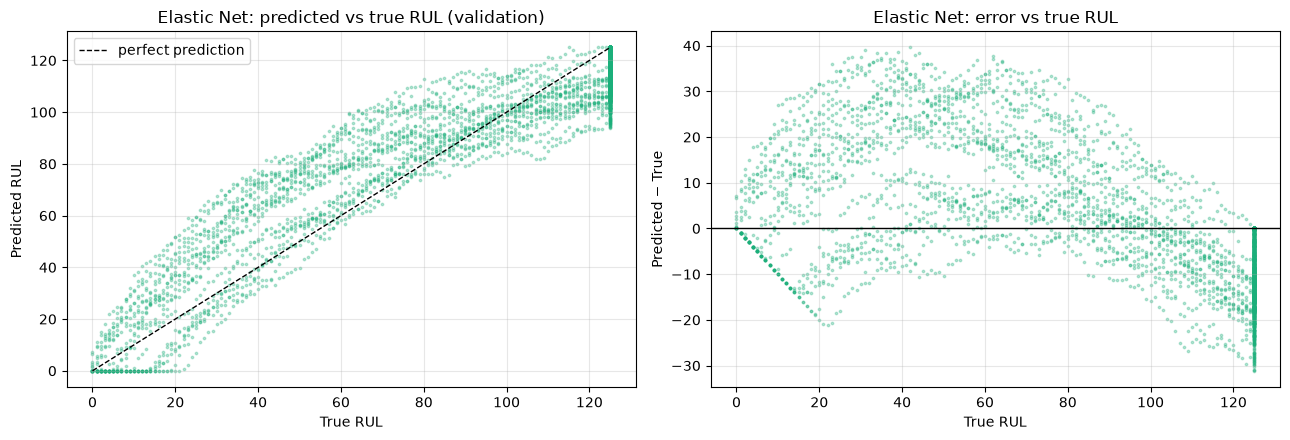

In [5]:
plot_validation(NAME, y_val, val_pred, "03_validation")

**How to read:** left — points on the dashed line are perfect predictions. Right — points above 0 mean the model
predicted **too much** life left (dangerous), below 0 means **too little** (safe but wasteful).

## 4. Which features matter?
For a linear model we look at the **weights**: big weight = big influence. Blue = more life left, red = less life left.

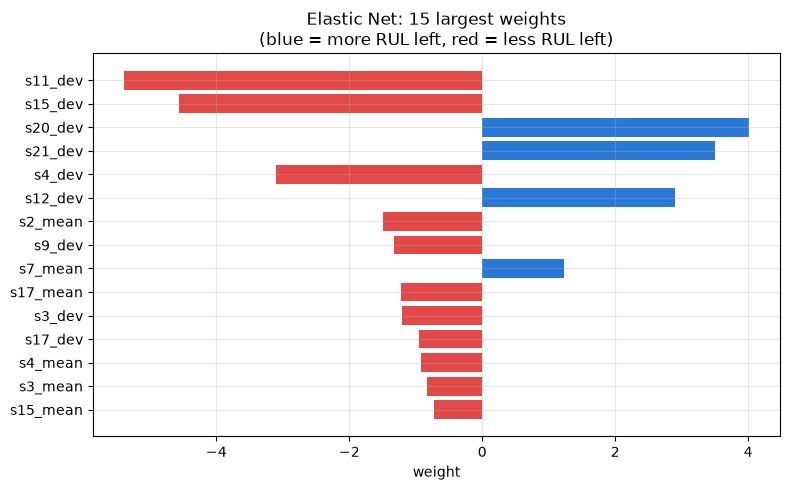

Elastic Net uses 36 of 71 features (the others got weight 0)


In [6]:
coef = pd.Series(model.named_steps["model"].coef_, index=FEATURES)
top = coef[coef.abs().nlargest(15).index]
plt.figure(figsize=(8, 5))
plt.barh(top.index[::-1], top.values[::-1], color=["#2a78d6" if v > 0 else "#e34948" for v in top.values[::-1]])
plt.title("Elastic Net: 15 largest weights\n(blue = more RUL left, red = less RUL left)"); plt.xlabel("weight")
savefig("03_elastic_net_weights")
print(f"Elastic Net uses {(coef != 0).sum()} of {len(coef)} features (the others got weight 0)")

## 5. Do the engineered features help?
Same model, same settings, but trained with **only the raw sensors + cycle** (15 features instead of 71).

In [7]:
RAW = [f for f in FEATURES if "_" not in f]   # cycle + 14 raw sensors
raw_model = clone(model).fit(X_train[RAW], y_train)
raw_rmse = evaluate(y_val, np.clip(raw_model.predict(val[RAW]), 0, RUL_CAP))["RMSE"]
eng_rmse = evaluate(y_val, val_pred)["RMSE"]

pd.DataFrame({"Validation RMSE": [raw_rmse, eng_rmse]},
             index=["Raw sensors only (15 features)", "With engineered features (71)"])

,Validation RMSE
Raw sensors only (15 features),17.96
With engineered features (71),15.04


## 6. Early vs late life
* **Early:** true RUL > 100 (engine still healthy)
* **Late:** true RUL ≤ 100 (engine is wearing out — the important part for maintenance)

In [8]:
stage_table(val["RUL_raw"], y_val, val_pred)

,Rows,RMSE,MAE
Stage,,,
early (RUL > 100),2050,12.51,10.20
late (RUL ≤ 100),2020,17.22,13.83


## 7. Official NASA test set (100 engines)
* Re-train the model with the same settings on **all 100 training engines**.
* Predict each test engine **once, at its last recorded cycle**, and compare with the true RUL from `RUL_FD001.txt`.
* Nothing is tuned on the test set.

In [9]:
final_model = clone(model).fit(train[FEATURES], train["RUL"])
test_pred = np.clip(final_model.predict(test[FEATURES]), 0, RUL_CAP)
pd.DataFrame([evaluate(test["RUL"], test_pred)], index=[NAME + " (test)"])

,RMSE,MAE,R2
Elastic Net (test),16.13,13.14,0.838


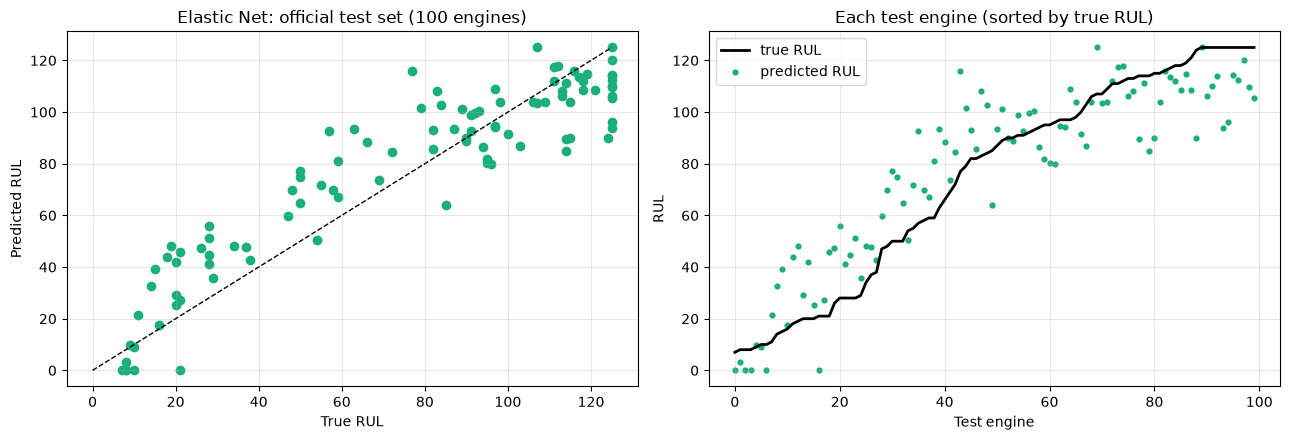

In [10]:
plot_test(NAME, test["RUL"], test_pred, "03_test")

## 8. Save the model and predictions (used by notebook 06 and the web app)

In [11]:
joblib.dump(final_model, MODELS / "elastic_net.joblib")
save_results(NAME, val, val_pred, test, test_pred, raw_rmse)

Saved predictions for Elastic Net in outputs/results/


## ✅ Summary — Elastic Net
* Simple and **easy to interpret** (each feature has a + or − weight).
* Clearly better than guessing the average, but **weaker than the tree models** because the link between sensors and
  RUL is **not a straight line** (sensors stay flat for a long time, then drift quickly).

**Viva quick answers**
* *Why scale the features?* The penalty treats all weights equally, so features must be on the same scale.
* *Why Elastic Net and not plain Linear Regression?* Many sensors are correlated; the penalty keeps the weights stable and removes useless features.